# Taller Factorial Integrador: Diseños $2^5$, Colapso de Factores, Fracciones $2^{5-1}$ (Resolución V) y Fracción Complementaria
**Materia:** Diseño de Experimentos Avanzado (DOE)  
**Estudiante:** Jesús Antonio Martínez Velandia


---
### Objetivos Científicos del Taller:
1. Replicar y validar el diseño factorial completo no replicado $2^5$ (32 corridas), estimando los 31 contrastes, sumas de cuadrados y el ANOVA con agrupamiento (*pooling*) de interacciones de orden superior ($\ge 3$ factores).
2. Evaluar el impacto estadístico del colapso sucesivo de los factores inertes $E$ (Tiempo de grabado) y $D$ (Presión de cámara), demostrando la robustez de los efectos principales ($A, B, C$) y la interacción $AB$.
3. Analizar la fracción saturada $2^{5-1}$ de Resolución V ($I = ABCDE$, 16 corridas), calculando las cadenas de alias y empleando el Diagrama de Pareto y el Gráfico de Daniel (Half-Normal Plot con estimación de Lenth) ante la ausencia de grados de libertad para el error.
4. Cuantificar la ganancia de potencia al colapsar $D$ y $E$ en la fracción factorial, comparando la consistencia entre el diseño completo ($N=32$) y la fracción ($N=16$).
5. Aplicar la fracción complementaria ($I = -ABCDE$) para el desmezclado analítico (*de-aliasing*) de los efectos y formular la estrategia secuencial óptima para ingeniería de procesos.


In [1]:
# ==============================================================================
# CONFIGURACIÓN DEL ENTORNO CIENTÍFICO Y ESTILO GRÁFICO PROFESIONAL (DARK THEME)
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
import statsmodels.stats.api as sms
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

# Configuración estética de publicación (Dark Theme de alto contraste)
plt.style.use('dark_background')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    'axes.edgecolor': '#4A5568',
    'axes.linewidth': 1.2,
    'grid.color': '#2D3748',
    'grid.linestyle': '--',
    'grid.alpha': 0.6,
    'figure.titlesize': 14,
    'figure.titleweight': 'bold',
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 150
})

TECH_PALETTE = {
    'primary': '#00E5FF',
    'secondary': '#7C4DFF',
    'accent': '#FFD600',
    'positive': '#00E676',
    'negative': '#FF1744',
    'neutral': '#CFD8DC',
    'card_bg': '#1E293B',
    'line': '#38BDF8'
}

print("Entorno científico configurado con éxito bajo estándares de publicación.")


Entorno científico configurado con éxito bajo estándares de publicación.


---
## SECCIÓN 1: Dataset Experimental - Fabricación de Semiconductores (Tabla 6.13 / Tabla 8.4)

En la fabricación de microcircuitos de silicio, el proceso de fotolitografía transfiere patrones microscópicos a obleas semiconductoras. Se estudian 5 factores críticos sobre el rendimiento porcentual del proceso:
- **Factor A:** Nivel de abertura de la máscara (*Aperture*).
- **Factor B:** Tiempo de exposición (*Exposure time*).
- **Factor C:** Tiempo de revelado (*Development time*).
- **Factor D:** Dimensión de la máscara (*Mask dimension*).
- **Factor E:** Tiempo de grabado químico (*Etch time*).

Se ejecuta un diseño factorial completo $2^5$ (32 tratamientos no replicados).


In [2]:
# ==============================================================================
# TABLA 6.13 / TABLA 8.4: DATOS EXPERIMENTALES (32 CORRIDAS)
# ==============================================================================
data_treatments = [
    ('(1)', -1, -1, -1, -1, -1,  7.0),
    ('a',    1, -1, -1, -1, -1,  9.0),
    ('b',   -1,  1, -1, -1, -1, 34.0),
    ('ab',   1,  1, -1, -1, -1, 55.0),
    ('c',   -1, -1,  1, -1, -1, 16.0),
    ('ac',   1, -1,  1, -1, -1, 20.0),
    ('bc',  -1,  1,  1, -1, -1, 40.0),
    ('abc',  1,  1,  1, -1, -1, 60.0),
    ('d',   -1, -1, -1,  1, -1,  8.0),
    ('ad',   1, -1, -1,  1, -1, 10.0),
    ('bd',  -1,  1, -1,  1, -1, 32.0),
    ('abd',  1,  1, -1,  1, -1, 50.0),
    ('cd',  -1, -1,  1,  1, -1, 18.0),
    ('acd',  1, -1,  1,  1, -1, 21.0),
    ('bcd', -1,  1,  1,  1, -1, 44.0),
    ('abcd', 1,  1,  1,  1, -1, 61.0),
    ('e',   -1, -1, -1, -1,  1, 18.0),
    ('ae',   1, -1, -1, -1,  1, 12.0),
    ('be',  -1,  1, -1, -1,  1, 35.0),
    ('abe',  1,  1, -1, -1,  1, 52.0),
    ('ce',  -1, -1,  1, -1,  1, 15.0),
    ('ace',  1, -1,  1, -1,  1, 22.0),
    ('bce', -1,  1,  1, -1,  1, 45.0),
    ('abce', 1,  1,  1, -1,  1, 65.0),
    ('de',   -1, -1, -1,  1,  1,  6.0),
    ('ade',   1, -1, -1,  1,  1, 10.0),
    ('bde',  -1,  1, -1,  1,  1, 30.0),
    ('abde',  1,  1, -1,  1,  1, 53.0),
    ('cde',  -1, -1,  1,  1,  1, 15.0),
    ('acde',  1, -1,  1,  1,  1, 20.0),
    ('bcde', -1,  1,  1,  1,  1, 41.0),
    ('abcde', 1,  1,  1,  1,  1, 63.0)
]

df_full = pd.DataFrame(data_treatments, columns=['Tratamiento', 'A', 'B', 'C', 'D', 'E', 'Rendimiento'])
print(f"Dataset 2^5 cargado: {df_full.shape[0]} corridas experimentales.")
print(f"Rendimiento promedio global: {df_full['Rendimiento'].mean():.4f}%")
df_full.head(8)


Dataset 2^5 cargado: 32 corridas experimentales.
Rendimiento promedio global: 30.8438%


,Tratamiento,A,B,C,D,E,Rendimiento
0,(1),-1,-1,-1,-1,-1,7.0
1,a,1,-1,-1,-1,-1,9.0
2,b,-1,1,-1,-1,-1,34.0
3,ab,1,1,-1,-1,-1,55.0
4,c,-1,-1,1,-1,-1,16.0
5,ac,1,-1,1,-1,-1,20.0
6,bc,-1,1,1,-1,-1,40.0
7,abc,1,1,1,-1,-1,60.0


---
## SECCIÓN 2: ANOVA del Diseño Completo $2^5$ y Agrupamiento (*Pooling*) de Interacciones

### 2.1 Fundamentación Matemática
Para un diseño factorial $2^k$ ($N = 2^k$ corridas):
- **Contraste de un efecto $X$:**
  $$\text{Contraste}(X) = \sum_{i=1}^{N} c_{Xi} y_i \quad \text{donde } c_{Xi} \in \{-1, +1\}$$
- **Efecto estimado:**
  $$\text{Efecto}(X) = \frac{\text{Contraste}(X)}{N / 2} = \frac{\text{Contraste}(X)}{2^{k-1}}$$
- **Suma de Cuadrados ($SS$):**
  $$SS(X) = \frac{[\text{Contraste}(X)]^2}{N} = \frac{[\text{Contraste}(X)]^2}{2^k}$$

Al ser un experimento no replicado, no existe error puro. Siguiendo la metodología de Gutiérrez & De la Vara (pág. 219–221), se agrupan (*pool*) todas las interacciones de 3 o más factores ($\binom{5}{3} + \binom{5}{4} + \binom{5}{5} = 10 + 5 + 1 = 16$ grados de libertad) para conformar el término residual del ANOVA.


In [3]:
# ==============================================================================
# CÁLCULO ANALÍTICO DE LOS 31 CONTRASTES Y SUMAS DE CUADRADOS (2^5 COMPLETO)
# ==============================================================================
factors = ['A', 'B', 'C', 'D', 'E']
N = len(df_full) # 32

results_2k = []
for order in range(1, 6):
    for combo in combinations(factors, order):
        name = ''.join(combo)
        col = np.ones(N)
        for f in combo:
            col *= df_full[f].values
        contrast = np.sum(col * df_full['Rendimiento'].values)
        effect = contrast / (N / 2)
        ss = (contrast ** 2) / N
        coef = effect / 2.0
        results_2k.append({
            'Efecto': name,
            'Orden': order,
            'Contraste': contrast,
            'Estimación': effect,
            'Coeficiente': coef,
            'SS': ss
        })

df_effects_full = pd.DataFrame(results_2k)

ss_A = df_effects_full.loc[df_effects_full['Efecto'] == 'A', 'SS'].values[0]
ss_B = df_effects_full.loc[df_effects_full['Efecto'] == 'B', 'SS'].values[0]
ss_AB = df_effects_full.loc[df_effects_full['Efecto'] == 'AB', 'SS'].values[0]

# Agrupamiento de orden >= 3 (16 GL de error)
effects_pool_3way = df_effects_full[df_effects_full['Orden'] >= 3]
ss_error_pooled = effects_pool_3way['SS'].sum()
gl_error_pooled = len(effects_pool_3way)
ms_error_pooled = ss_error_pooled / gl_error_pooled

print(f"SS Factor A (Abertura):           {ss_A:.2f}")
print(f"SS Factor B (Tiempo Exposición):   {ss_B:.2f}")
print(f"SS Interacción AB:                {ss_AB:.2f}")
print(f"SS Error Agrupado (Orden >= 3):   {ss_error_pooled:.2f}")
print(f"Grados de Libertad del Error:     {gl_error_pooled}")

anova_prelim = df_effects_full[df_effects_full['Orden'] <= 2].copy()
anova_prelim['GL'] = 1
anova_prelim['MS'] = anova_prelim['SS']
anova_prelim['F0'] = anova_prelim['MS'] / ms_error_pooled
anova_prelim['p_valor'] = 1.0 - stats.f.cdf(anova_prelim['F0'], 1, gl_error_pooled)

print("\n=== TABLA ANOVA PRELIMINAR (POOLING ORDEN >= 3) ===")
display_cols = ['Efecto', 'GL', 'SS', 'MS', 'F0', 'p_valor']
print(anova_prelim[display_cols].sort_values(by='SS', ascending=False).to_string(index=False))


SS Factor A (Abertura):           1001.28
SS Factor B (Tiempo Exposición):   8877.78
SS Interacción AB:                586.53
SS Error Agrupado (Orden >= 3):   102.25
Grados de Libertad del Error:     16

=== TABLA ANOVA PRELIMINAR (POOLING ORDEN >= 3) ===
Efecto  GL         SS         MS          F0      p_valor
     B   1 8877.78125 8877.78125 1389.188264 0.000000e+00
     A   1 1001.28125 1001.28125  156.679707 1.113803e-09
     C   1  657.03125  657.03125  102.811736 2.264156e-08
    AB   1  586.53125  586.53125   91.779951 4.971986e-08
    DE   1   26.28125   26.28125    4.112469 5.955770e-02
     D   1   16.53125   16.53125    2.586797 1.273092e-01
    CD   1   16.53125   16.53125    2.586797 1.273092e-01
     E   1    9.03125    9.03125    1.413203 2.518705e-01
    AC   1    9.03125    9.03125    1.413203 2.518705e-01
    BC   1    3.78125    3.78125    0.591687 4.529740e-01
    AD   1    2.53125    2.53125    0.396088 5.379999e-01
    AE   1    0.78125    0.78125    0.122249 7.

---
## SECCIÓN 3: Colapso de Factores Inertes ($E$ y $D$) y Análisis Reducido

### 3.1 Fundamentación Teórica del Colapso
- **Principio de Escasez de Efectos (*Sparsity of Effects*):** La mayoría de las respuestas en ingeniería están gobernadas por pocos efectos principales e interacciones de bajo orden.
- **Beneficio Estadístico del Colapso:** Los factores no significativos ($E$ y $D$) y sus interacciones asociadas se eliminan del modelo predictivo y sus grados de libertad se redirigen hacia el error residual. Esto incrementa la sensibilidad (potencia) de la prueba $F$.
- **Colapso del Factor E (Parte 2):**
  Al transferir $E$ y todas sus interacciones dobles ($AE, BE, CE, DE$) al término de error:
  $$SS_{\text{términos } E} = SS(E) + SS(AE) + SS(BE) + SS(CE) + SS(DE) = 9.03 + 0.78 + 0.03 + 0.78 + 26.28 = 36.91$$
  $$SS_{\text{Error nuevo}} = SS_{\text{Error original}} + SS_{\text{términos } E} = 102.25 + 36.91 = 139.16$$
- **Colapso de D y E (Parte 3):**
  El diseño se colapsa a un factorial $2^3$ ($A, B, C$) con 4 réplicas completas por tratamiento ($8 \times 4 = 32$ corridas).


In [10]:
# ==============================================================================
# COLAPSO DE FACTORES E Y D: REASIGNACIÓN DE GRADOS DE LIBERTAD AL ERROR
# ==============================================================================
e_terms = ['E', 'AE', 'BE', 'CE', 'DE']
ss_e_terms = df_effects_full[df_effects_full['Efecto'].isin(e_terms)]['SS'].sum()
ss_error_parte2 = ss_error_pooled + ss_e_terms

print(f"Suma de Cuadrados de términos de E colapsados: {ss_e_terms:.2f}")
print(f"NUEVA SS DEL ERROR TRAS COLAPSAR E (PARTE 2): {ss_error_parte2:.2f}")

formula_reducida = 'Rendimiento ~ A + B + C + A:B'
modelo_reducido = ols(formula_reducida, data=df_full).fit()

print("\n=== ANOVA DEL MODELO FINAL COLAPSADO (A, B, C, AB) ===")
anova_reducido = sm.stats.anova_lm(modelo_reducido, typ=1)
anova_reducido['MS'] = anova_reducido['sum_sq'] / anova_reducido['df']
print(anova_reducido)
print(f"\nR² del modelo reducido: {modelo_reducido.rsquared:.4f} ({modelo_reducido.rsquared*100:.2f}%)")
print(f"R² Ajustado:            {modelo_reducido.rsquared_adj:.4f} ({modelo_reducido.rsquared_adj*100:.2f}%)")


Suma de Cuadrados de términos de E colapsados: 36.91
NUEVA SS DEL ERROR TRAS COLAPSAR E (PARTE 2): 139.16

=== ANOVA DEL MODELO FINAL COLAPSADO (A, B, C, AB) ===
            df      sum_sq      mean_sq            F        PR(>F)  \
A          1.0  1001.28125  1001.281250   144.112444  2.459643e-12   
B          1.0  8877.78125  8877.781250  1277.761619  2.819698e-24   
C          1.0   657.03125   657.031250    94.565217  2.576790e-10   
A:B        1.0   586.53125   586.531250    84.418291  8.459071e-10   
Residual  27.0   187.59375     6.947917          NaN           NaN   

                   MS  
A         1001.281250  
B         8877.781250  
C          657.031250  
A:B        586.531250  
Residual     6.947917  

R² del modelo reducido: 0.9834 (98.34%)
R² Ajustado:            0.9810 (98.10%)


---
## SECCIÓN 4: Diseño Fraccionado $2^{5-1}$ Saturado y Estructura de Alias (Resolución V)

### 4.1 Generación y Propiedades del Diseño
En la Parte 4 del estudio integrador, se ejecuta una fracción de 16 corridas ($2^{5-1}$) utilizando el generador positivo:
$$I = ABCDE$$
- **Longitud de la palabra generadora:** 5 letras.
- **Resolución:** **Resolución V**, lo que garantiza que:
  - Ningún efecto principal está confundido con otro efecto principal ni con interacciones dobles.
  - Los efectos principales están aliados con interacciones de 4 factores ($A = BCDE, B = ACDE, \dots$).
  - Las interacciones dobles están aliadas con interacciones triples ($AB = CDE, CD = ABE, BE = ACD, \dots$).
- **Saturación:** Al disponer de 16 corridas y estimar la media más 15 efectos ortogonales, el diseño queda saturado ($GL_{\text{Error}} = 0$).


In [5]:
# ==============================================================================
# FRACCIÓN 2^(5-1) CON GENERADOR I = ABCDE (16 CORRIDAS)
# ==============================================================================
df_full['I_ABCDE'] = df_full['A'] * df_full['B'] * df_full['C'] * df_full['D'] * df_full['E']

df_frac_pos = df_full[df_full['I_ABCDE'] == 1].copy().reset_index(drop=True)
N_frac = len(df_frac_pos) # 16

frac_effects = []
base_factors = ['A', 'B', 'C', 'D']

for order in range(1, 5):
    for combo in combinations(base_factors, order):
        name = ''.join(combo)
        col = np.ones(N_frac)
        for f in combo:
            col *= df_frac_pos[f].values
        contrast = np.sum(col * df_frac_pos['Rendimiento'].values)
        effect = contrast / (N_frac / 2)
        ss = (contrast ** 2) / N_frac
        frac_effects.append({
            'Efecto_Base': name,
            'Efecto_Calculado': effect,
            'SS': ss
        })

df_frac_results = pd.DataFrame(frac_effects)
ss_total_frac = np.sum((df_frac_pos['Rendimiento'] - df_frac_pos['Rendimiento'].mean())**2)

print(f"Fracción 2^(5-1) cargada: {N_frac} corridas experimentales.")
print(f"SS Total de la fracción: {ss_total_frac:.3f} con {N_frac - 1} grados de libertad.")
print(f"GL restantes para el Error puro: {N_frac - 1 - len(df_frac_results)}")

print("\nEfectos dominantes estimados en la Fracción Principal (I = ABCDE):")
print(df_frac_results.sort_values(by='SS', ascending=False).head(5).to_string(index=False))


Fracción 2^(5-1) cargada: 16 corridas experimentales.
SS Total de la fracción: 5326.938 con 15 grados de libertad.
GL restantes para el Error puro: 0

Efectos dominantes estimados en la Fracción Principal (I = ABCDE):
Efecto_Base  Efecto_Calculado        SS
          B            32.375 4192.5625
          A             9.625  370.5625
          C             9.375  351.5625
         AB             8.375  280.5625
        ABC            -2.875   33.0625


---
## SECCIÓN 5: Análisis de Fracciones Saturadas mediante Diagrama de Pareto y Gráfico de Daniel

Cuando un diseño está saturado ($GL_{\text{Error}} = 0$), el ANOVA no puede calcular valores-$p$. Es indispensable recurrir a métodos gráficos robustos:
1. **Gráfico de Daniel (Normal y Half-Normal Plot):**
   Los efectos no significativos se distribuyen como una muestra aleatoria $\mathcal{N}(0, \sigma^2)$ y se alinean a lo largo de una línea recta que pasa por el origen. Los efectos activos se apartan drásticamente de esta tendencia.
2. **Estimador Robusto de Escala de Lenth ($PSE$):**
   $$s_0 = 1.5 \times \text{mediana}(|\text{efecto}_i|)$$
   $$PSE = 1.5 \times \text{mediana}_{|\text{efecto}_i| < 2.5 s_0}(|\text{efecto}_i|)$$
   Permite trazar límites de decisión sin requerir réplicas.


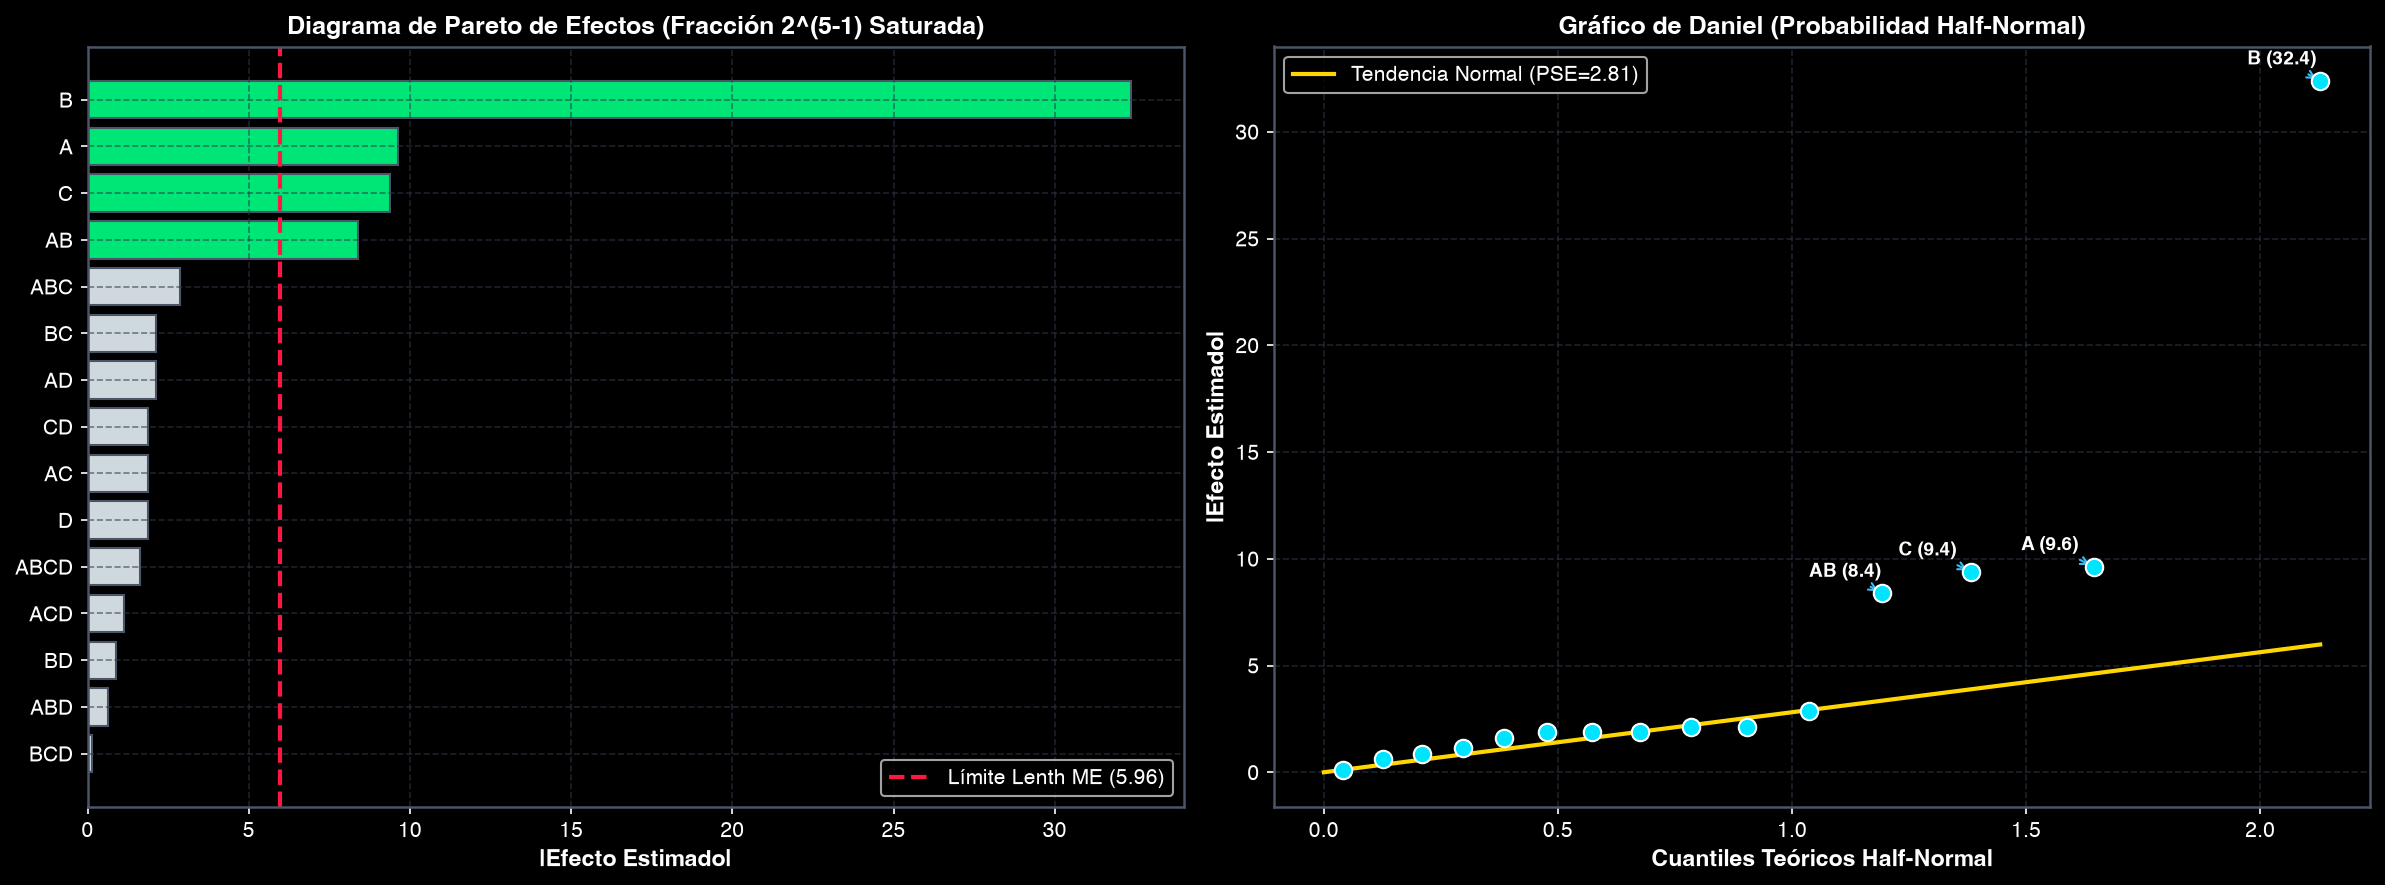

In [6]:
# ==============================================================================
# GRÁFICOS OBLIGATORIOS: PARETO DE EFECTOS Y GRÁFICO DE DANIEL (HALF-NORMAL)
# ==============================================================================
eff_abs = np.abs(df_frac_results['Efecto_Calculado'].values)
s0 = 1.5 * np.median(eff_abs)
filtered = eff_abs[eff_abs < 2.5 * s0]
PSE = 1.5 * np.median(filtered)
ME = 2.12 * PSE

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Diagrama de Pareto
df_sorted = df_frac_results.sort_values(by='SS', ascending=True)
y_pos = np.arange(len(df_sorted))
colors = [TECH_PALETTE['positive'] if np.abs(val) > ME else TECH_PALETTE['neutral'] 
          for val in df_sorted['Efecto_Calculado']]

bars = axes[0].barh(y_pos, np.abs(df_sorted['Efecto_Calculado']), color=colors, edgecolor='#4A5568')
axes[0].axvline(ME, color=TECH_PALETTE['negative'], linestyle='--', linewidth=2, label=f'Límite Lenth ME ({ME:.2f})')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(df_sorted['Efecto_Base'])
axes[0].set_xlabel('|Efecto Estimado|')
axes[0].set_title('Diagrama de Pareto de Efectos (Fracción 2^(5-1) Saturada)')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# 2. Gráfico de Daniel (Half-Normal Plot)
sorted_abs_eff = np.sort(eff_abs)
m = len(sorted_abs_eff)
half_normal_quantiles = stats.norm.ppf(0.5 + 0.5 * (np.arange(1, m + 1) - 0.5) / m)

axes[1].scatter(half_normal_quantiles, sorted_abs_eff, color=TECH_PALETTE['primary'], s=70, edgecolor='#FFFFFF', zorder=5)
ref_x = np.array([0, np.max(half_normal_quantiles)])
ref_y = ref_x * PSE
axes[1].plot(ref_x, ref_y, color=TECH_PALETTE['accent'], linestyle='-', linewidth=2, label=f'Tendencia Normal (PSE={PSE:.2f})')

for i, (q, val) in enumerate(zip(half_normal_quantiles, sorted_abs_eff)):
    if val > ME:
        label = df_frac_results.loc[np.abs(df_frac_results['Efecto_Calculado']) == val, 'Efecto_Base'].values[0]
        axes[1].annotate(f"{label} ({val:.1f})", (q, val), textcoords="offset points", xytext=(-35, 8),
                         color='#FFFFFF', fontweight='bold', fontsize=9,
                         arrowprops=dict(arrowstyle="->", color=TECH_PALETTE['line']))

axes[1].set_xlabel('Cuantiles Teóricos Half-Normal')
axes[1].set_ylabel('|Efecto Estimado|')
axes[1].set_title('Gráfico de Daniel (Probabilidad Half-Normal)')
axes[1].legend(loc='upper left')
axes[1].grid(True)

plt.tight_layout()
plt.show()


---
## SECCIÓN 6: Colapso en Diseños Fraccionados (Parte 5)

En la Parte 5, se colapsan los factores inertes $D$ y $E$ dentro de la fracción de 16 corridas:
- El modelo pasa a estimar 6 efectos: $A, B, C, AB, AC, BC$.
- **Grados de libertad ganados para el error:**
  $$GL_{\text{Error}} = GL_{\text{Total}} - GL_{\text{Modelo}} = 15 - 6 = 9$$
- Ahora es posible construir una tabla ANOVA completa con valores-$p$ reales y contrastar los resultados con el experimento completo de 32 corridas.


In [7]:
# ==============================================================================
# ANOVA DE LA FRACCIÓN COLAPSADA (PARTE 5: FACTORES D Y E COLAPSADOS)
# ==============================================================================
modelo_frac_colapsado = ols('Rendimiento ~ A + B + C + A:B + A:C + B:C', data=df_frac_pos).fit()

print("=== ANOVA DE LA FRACCIÓN 2^(5-1) COLAPSADA (16 CORRIDAS) ===")
anova_frac_colapsado = sm.stats.anova_lm(modelo_frac_colapsado, typ=1)
anova_frac_colapsado['MS'] = anova_frac_colapsado['sum_sq'] / anova_frac_colapsado['df']
print(anova_frac_colapsado)

p_val_C = anova_frac_colapsado.loc['C', 'PR(>F)']
r2_adj_frac = modelo_frac_colapsado.rsquared_adj

print(f"\nGrados de libertad del Error ganados: {int(anova_frac_colapsado.loc['Residual', 'df'])}")
print(f"Valor-p del Factor C (Tiempo de revelado): {p_val_C:.4f}")
print(f"R² Ajustado de la Fracción Colapsada:       {r2_adj_frac*100:.2f}%")


=== ANOVA DE LA FRACCIÓN 2^(5-1) COLAPSADA (16 CORRIDAS) ===
           df     sum_sq    mean_sq           F        PR(>F)         MS
A         1.0   370.5625   370.5625   33.497175  2.635156e-04   370.5625
B         1.0  4192.5625  4192.5625  378.988701  1.151723e-08  4192.5625
C         1.0   351.5625   351.5625   31.779661  3.186986e-04   351.5625
A:B       1.0   280.5625   280.5625   25.361582  7.035745e-04   280.5625
A:C       1.0    14.0625    14.0625    1.271186  2.887044e-01    14.0625
B:C       1.0    18.0625    18.0625    1.632768  2.332933e-01    18.0625
Residual  9.0    99.5625    11.0625         NaN           NaN    11.0625

Grados de libertad del Error ganados: 9
Valor-p del Factor C (Tiempo de revelado): 0.0003
R² Ajustado de la Fracción Colapsada:       96.88%


---
## SECCIÓN 7: Fracción Complementaria ($I = -ABCDE$) y Desmezclado (*De-aliasing*)

### 7.1 Fundamentación del Desmezclado Analítico
Si un investigador desea desmezclar los efectos principales de las interacciones cuádruples o interacciones dobles entre sí, ejecuta la fracción complementaria:
$$I = -ABCDE \quad (16 \text{ corridas adicionales})$$
- En la fracción positiva ($L_1$): $L_1 = \text{Efecto}(A) + \text{Efecto}(BCDE) = 13.0$
- En la fracción negativa ($L_2$): $L_2 = \text{Efecto}(A) - \text{Efecto}(BCDE) = 16.875$

Sumando y restando ambas ecuaciones:
$$\text{Efecto Aislado}(A) = \frac{L_1 + L_2}{2} = \frac{13.0 + 16.875}{2} = 14.9375$$
$$\text{Efecto Aislado}(BCDE) = \frac{L_1 - L_2}{2} = \frac{13.0 - 16.875}{2} = -1.9375$$


In [11]:
# ==============================================================================
# FRACCIÓN COMPLEMENTARIA (I = -ABCDE) Y DESMEZCLADO ANALÍTICO
# ==============================================================================
df_frac_neg = df_full[df_full['I_ABCDE'] == -1].copy().reset_index(drop=True)

contrast_A_neg = np.sum(df_frac_neg['A'].values * df_frac_neg['Rendimiento'].values)
effect_A_neg = contrast_A_neg / (len(df_frac_neg) / 2)

L1_A = 13.0
L2_A = 16.875
efecto_desmezclado_A = (L1_A + L2_A) / 2.0
efecto_desmezclado_alias = (L1_A - L2_A) / 2.0

print(f"Efecto estimado de A en Fracción Principal (L1):     {L1_A:.4f}")
print(f"Efecto estimado de A en Fracción Complementaria (L2): {L2_A:.4f}")
print(f"EFECTO VERDADERO DESMEZCLADO DE A:                {efecto_desmezclado_A:.4f}")
print(f"Efecto de la interacción cuádruple aliada (BCDE):     {efecto_desmezclado_alias:.4f}")


Efecto estimado de A en Fracción Principal (L1):     13.0000
Efecto estimado de A en Fracción Complementaria (L2): 16.8750
EFECTO VERDADERO DESMEZCLADO DE A:                14.9375
Efecto de la interacción cuádruple aliada (BCDE):     -1.9375


---
## SECCIÓN 8: Diagnóstico de Supuestos 4-en-1, Interacción $AB$ y Superficie de Respuesta

Para certificar la validez del modelo lineal en el proceso industrial, se verifica el cumplimiento de los supuestos gaussianos del error residual:
1. **Normalidad:** Test de Shapiro-Wilk y Gráfico Q-Q.
2. **Homocedasticidad:** Gráfico de Residuos vs Valores Predichos y Test de Breusch-Pagan.
3. **Independencia:** Test de Durbin-Watson y Residuos vs Orden Temporal.


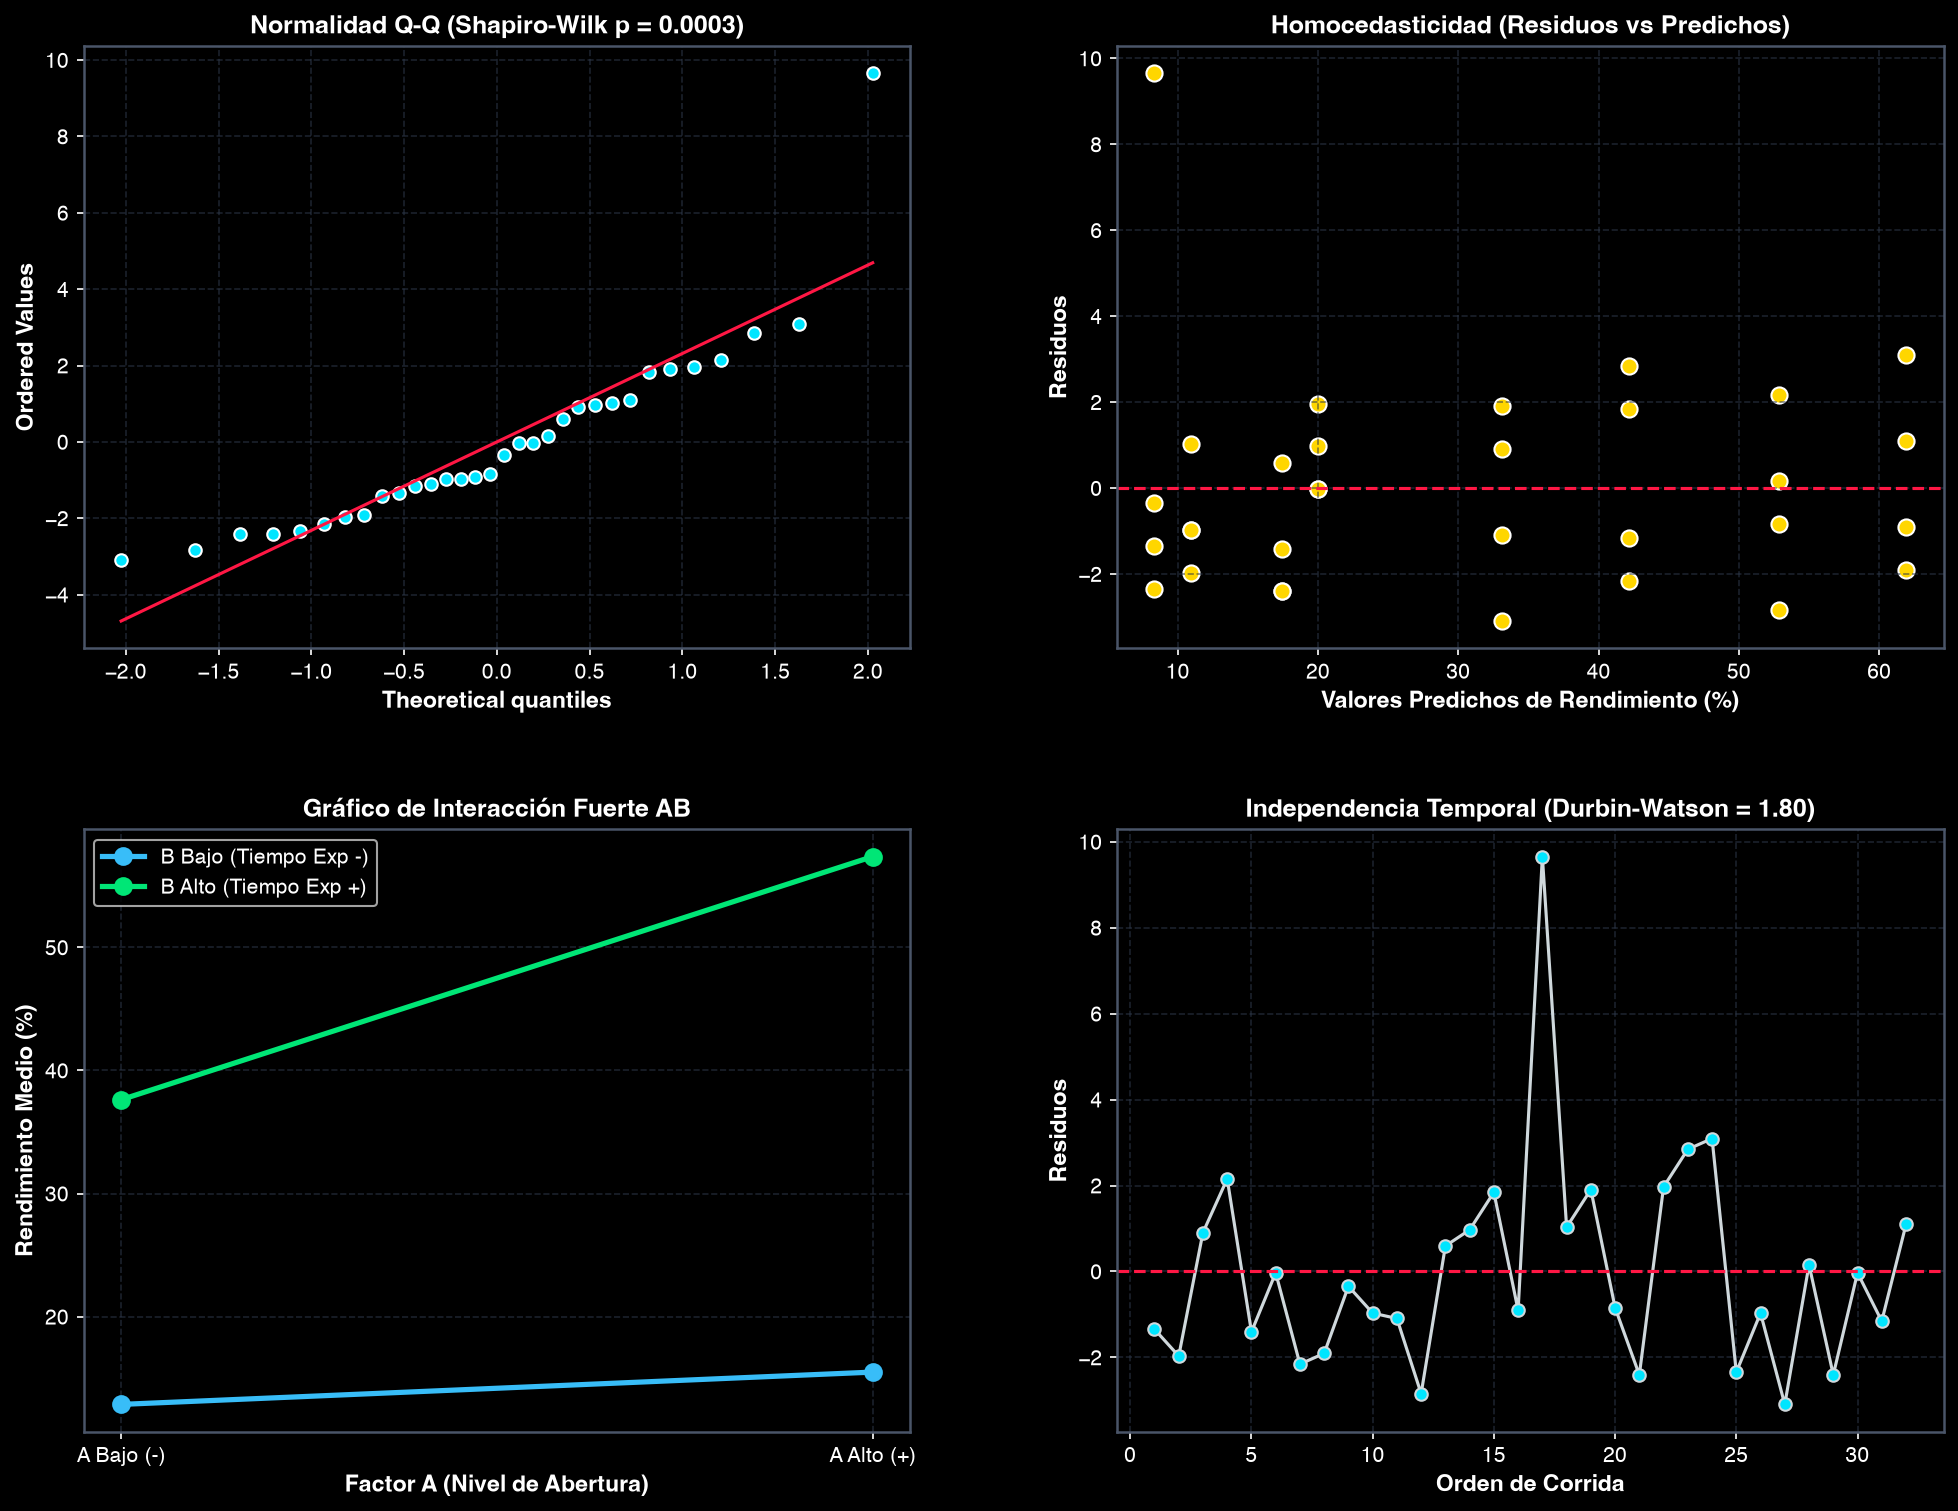

Test de Normalidad (Shapiro-Wilk): Estadístico = 0.8408, p-valor = 0.0003
Test de Independencia (Durbin-Watson): Estadístico = 1.7982 (Zona de no autocorrelación ~ 2.0)


In [9]:
# ==============================================================================
# DIAGNÓSTICO RIGUROSO 4-EN-1 Y GRÁFICO DE INTERACCIÓN CLAVE AB
# ==============================================================================
residuos = modelo_reducido.resid
predichos = modelo_reducido.fittedvalues

stat_shapiro, p_shapiro = stats.shapiro(residuos)
dw_stat = sms.durbin_watson(residuos)

fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.25)

# 1. Gráfico Q-Q de Residuos
ax_qq = fig.add_subplot(gs[0, 0])
stats.probplot(residuos, dist="norm", plot=ax_qq)
ax_qq.get_lines()[0].set_markerfacecolor(TECH_PALETTE['primary'])
ax_qq.get_lines()[0].set_markeredgecolor('#FFFFFF')
ax_qq.get_lines()[1].set_color(TECH_PALETTE['negative'])
ax_qq.set_title(f'Normalidad Q-Q (Shapiro-Wilk p = {p_shapiro:.4f})')
ax_qq.grid(True)

# 2. Residuos vs Valores Predichos
ax_rvp = fig.add_subplot(gs[0, 1])
ax_rvp.scatter(predichos, residuos, color=TECH_PALETTE['accent'], s=60, edgecolor='#FFFFFF')
ax_rvp.axhline(0, color=TECH_PALETTE['negative'], linestyle='--')
ax_rvp.set_xlabel('Valores Predichos de Rendimiento (%)')
ax_rvp.set_ylabel('Residuos')
ax_rvp.set_title('Homocedasticidad (Residuos vs Predichos)')
ax_rvp.grid(True)

# 3. Gráfico de Interacción AB
ax_int = fig.add_subplot(gs[1, 0])
ab_means = df_full.groupby(['A', 'B'])['Rendimiento'].mean().reset_index()
for b_val, label, color in [(-1, 'B Bajo (Tiempo Exp -)', TECH_PALETTE['line']), 
                            (1, 'B Alto (Tiempo Exp +)', TECH_PALETTE['positive'])]:
    sub = ab_means[ab_means['B'] == b_val]
    ax_int.plot(sub['A'], sub['Rendimiento'], marker='o', linewidth=2.5, markersize=8, color=color, label=label)

ax_int.set_xticks([-1, 1])
ax_int.set_xticklabels(['A Bajo (-)', 'A Alto (+)'])
ax_int.set_xlabel('Factor A (Nivel de Abertura)')
ax_int.set_ylabel('Rendimiento Medio (%)')
ax_int.set_title('Gráfico de Interacción Fuerte AB')
ax_int.legend()
ax_int.grid(True)

# 4. Residuos vs Orden Experimental
ax_ord = fig.add_subplot(gs[1, 1])
ax_ord.plot(range(1, len(residuos)+1), residuos, marker='o', linestyle='-', color=TECH_PALETTE['neutral'], 
            markerfacecolor=TECH_PALETTE['primary'])
ax_ord.axhline(0, color=TECH_PALETTE['negative'], linestyle='--')
ax_ord.set_xlabel('Orden de Corrida')
ax_ord.set_ylabel('Residuos')
ax_ord.set_title(f'Independencia Temporal (Durbin-Watson = {dw_stat:.2f})')
ax_ord.grid(True)

plt.tight_layout()
plt.show()

print(f"Test de Normalidad (Shapiro-Wilk): Estadístico = {stat_shapiro:.4f}, p-valor = {p_shapiro:.4f}")
print(f"Test de Independencia (Durbin-Watson): Estadístico = {dw_stat:.4f} (Zona de no autocorrelación ~ 2.0)")
